
#1. Carga del conjunto de datos publico
En esta celda importamos las librerías necesarias (`pandas`, `numpy`, `matplotlib`, `scikit-learn`) y cargamos el dataset original de Diabetes de los indios Pima directamente desde una URL pública, asignándole los nombres correctos a cada columna.



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# URL pública del dataset de Diabetes
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


# 2- Analisis exploratorio y visualizacion


2. Descripción Estadística
Utilizamos el método describe() para obtener un resumen estadístico rápido de las variables numéricas (como la media, desviación estándar, mínimos, máximos y percentiles) para identificar posibles anomalías en los datos.

In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


3. Información General del DataFrame
Con el método info() verificamos la estructura del DataFrame, confirmando los tipos de datos de cada columna y asegurándonos de que no existan valores nulos declarados explícitamente (non-null).

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


4. Segmentación por Clase
Separamos el conjunto de datos original en dos DataFrames distintos basándonos en la variable objetivo Outcome: un grupo para personas sin diabetes (df_oc0) y otro para personas con diabetes (df_oc1).

In [6]:
df_oc0= df[df['Outcome'] == 0 ]
df_oc1= df[df['Outcome'] == 1 ]

5. Visualización de Relaciones (Dispersión)
Creamos un gráfico de dispersión (Scatter Plot) cruzando la concentración de Glucose contra el BMI (Índice de Masa Corporal). Representamos con color azul a los pacientes sin diabetes y con gris a aquellos diagnosticados con diabetes.

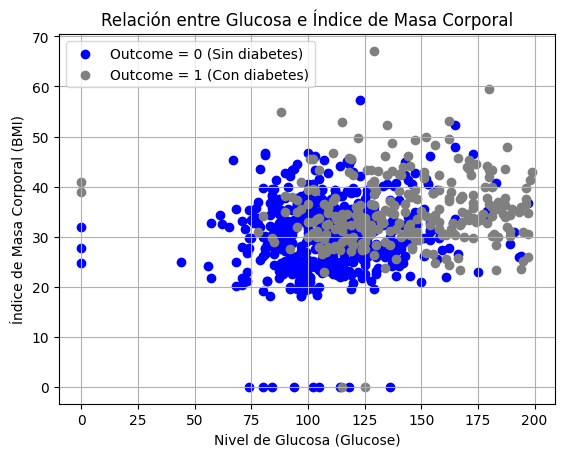

In [11]:
plt.scatter(df_oc0['Glucose'],df_oc0['BMI'],c='blue', label='Outcome = 0 (Sin diabetes)')
plt.scatter(df_oc1['Glucose'],df_oc1['BMI'],c='gray', label='Outcome = 1 (Con diabetes)')
plt.xlabel('Nivel de Glucosa (Glucose)')
plt.ylabel('Índice de Masa Corporal (BMI)')

plt.title('Relación entre Glucosa e Índice de Masa Corporal')
plt.legend()
plt.grid(True)
plt.show()

6. Balance de Clases
Contamos de forma cuantitativa cuántas instancias pertenecen a la clase con diabetes (1) y cuántas a la clase sin diabetes (0) para analizar el desbalance original del dataset.

In [12]:
x = (df['Outcome'] == 1).sum()
y=(df['Outcome'] == 0).sum()
print(x)
print(y)

268
500


### 7. Identificación de Valores Cero Atípicos
Aunque en la información general no se reportan valores nulos, en medicina un valor de 0 en variables como la glucosa, la presión arterial o el grosor de la piel no es biológicamente posible. Reemplazamos los ceros por nulos para identificar cuántos valores faltantes reales tenemos por columna.

In [14]:
# Reemplazamos temporalmente todos los ceros por NaN para explorar valores faltantes.
# Nota: En 'Pregnancies' y 'Outcome' el 0 sí es un valor válido y no representa un dato faltante.
df_nulos = df[df!=0]
df.info()
df_nulos.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


# 3. Limpieza y Preprocesamiento de Datos

8. Limpieza de Datos e Imputación
En esta etapa realizamos tres acciones clave:

Creamos una copia del dataset y convertimos los valores de 0 de las columnas clínicas atípicas en nulos.
Submuestreamos la clase mayoritaria (eliminamos la mitad de las filas donde Outcome es 1) para balancear o ajustar la distribución.
Imputamos (llenamos) los valores nulos resultantes utilizando la mediana de cada columna respectiva.

In [59]:
#creamos un df_null el cual marcara nulos en cada una de nuestras columnas atipicas, para despues corregirlas en una df_c (el df correcto )
df_null = df.copy()
c_atipicas = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
df_null[c_atipicas] = df[c_atipicas][df[c_atipicas] != 0]
#checamos los valores de mediana para cada Outcome
print(df_null.groupby('Outcome').median())
df_c = df_null.copy()
#despues remplazamos los valores de las columnas afectadas en base a su outcome ejemplo la glucosa para un outcome positivo y nulo sea 140 mientras que para uno negativo 107
#el metodo que nos permite modificar solo las columnas atipicas es el transform el cual aplica (median) dependiendo el outcome a nuestros nulos
df_c[c_atipicas] = df_c[c_atipicas].fillna(df_null.groupby('Outcome')[c_atipicas].transform('median'))
df_c.head()

         Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
Outcome                                                                      
0                2.0    107.0           70.0           27.0    102.5  30.1   
1                4.0    140.0           74.5           32.0    169.5  34.3   

         DiabetesPedigreeFunction   Age  
Outcome                                  
0                           0.336  27.0  
1                           0.449  36.0  


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,206.846154,33.6,0.627,50,1
1,1,85.0,66.0,29.0,130.287879,26.6,0.351,31,0
2,8,183.0,64.0,33.0,206.846154,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.000000,43.1,2.288,33,1


9. Tratamiento de Valores Atípicos (Outliers)
Aplicamos la técnica del Rango Intercuartílico (IQR) sobre la variable Insulin. Calculamos los límites inferior y superior para filtrar el dataset (df_f) y remover los registros que se consideren atípicos o extremos.

In [69]:
# aqui aplicamos un normalizacion de valores mediante a lo mencionado IQR y lo guardamos en una df_f(df final xd)
Q1 = np.percentile(df_c['Insulin'],25)
Q3= np.percentile(df_c['Insulin'],75)
IQR = Q3-Q1
LS= Q3+(1.5*IQR)
LI = Q1 - (1.5*IQR)
df_f = df_c[(df_c['Insulin']>=LI) & (df_c['Insulin']<=LS )]
df_f.isnull().sum()
df_f.describe()
df_f.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,206.846154,33.6,0.627,50,1
1,1,85.0,66.0,29.0,130.287879,26.6,0.351,31,0
2,8,183.0,64.0,33.0,206.846154,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.000000,43.1,2.288,33,1


# 4. Entrenamiento y Evaluación del Árbol de Decisión

10. Entrenamiento del Árbol de Decisión
Definimos las variables independientes (X) y la variable objetivo (y). Dividimos los datos en entrenamiento (75%) y prueba (25%), ajustamos un modelo de árbol de decisión limitado a una profundidad máxima de 4 niveles para evitar el sobreajuste, evaluamos el modelo y finalmente graficamos la estructura del árbol generado.

--- Evaluación del Modelo ---
Exactitud Global (Accuracy): 0.9086

Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93       126
           1       0.86      0.85      0.86        60

    accuracy                           0.91       186
   macro avg       0.90      0.89      0.89       186
weighted avg       0.91      0.91      0.91       186



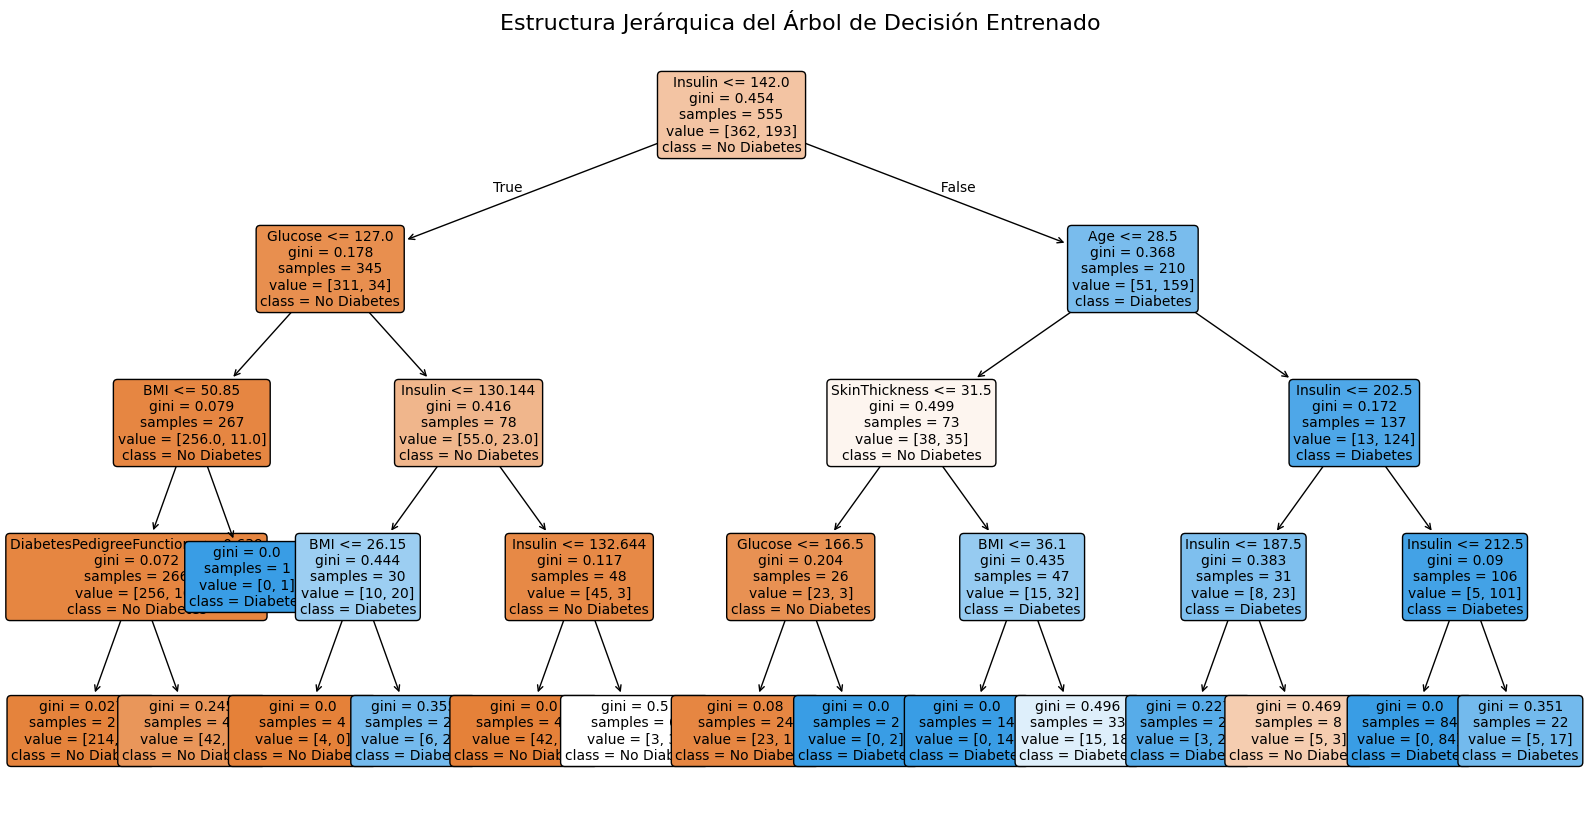

In [70]:
# 1. Separación de características independientes (X) y variable objetivo (y)
# Usamos tu DataFrame corregido 'df_f'
X = df_f.drop(columns=['Outcome'])
y = df_f['Outcome']

# 2. Partición del conjunto (75% Entrenamiento, 25% Prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 3. Inicialización y entrenamiento del modelo
modelo_arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_arbol.fit(X_train, y_train)

# 4. Generación de predicciones y cálculo de métricas de desempeño
y_pred = modelo_arbol.predict(X_test)
exactitud = accuracy_score(y_test, y_pred)

print("--- Evaluación del Modelo ---")
print(f"Exactitud Global (Accuracy): {exactitud:.4f}")
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred))

# 5. Visualización de la Estructura Jerárquica del Árbol
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_arbol,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura Jerárquica del Árbol de Decisión Entrenado", fontsize=16)
plt.show()

#11. Matriz de Confusión
Calculamos y visualizamos la matriz de confusión. Esto nos permite ver detalladamente la cantidad de verdaderos positivos, falsos positivos, verdaderos negativos y falsos negativos que obtuvo nuestro modelo durante la fase de prueba.

--- Matriz de Confusión (Numérica) ---
[[118   8]
 [  9  51]]


<Figure size 600x500 with 0 Axes>

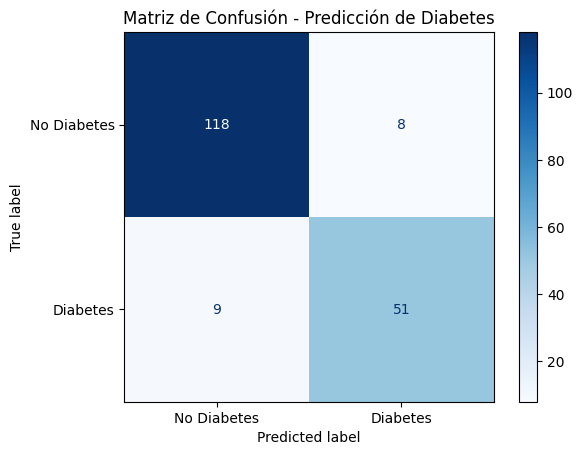

In [71]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
matriz = confusion_matrix(y_test, y_pred)

print("--- Matriz de Confusión (Numérica) ---")
print(matriz)

# 2. Graficar la matriz de confusión de forma visual
plt.figure(figsize=(6, 5))
vis_matriz = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['No Diabetes', 'Diabetes']
)

# Dibujar la matriz con un mapa de colores (puedes cambiar 'Blues' por 'Oranges' o 'Purples')
vis_matriz.plot(cmap='Blues', values_format='d')

plt.title('Matriz de Confusión - Predicción de Diabetes')
plt.grid(False) # Desactivamos las líneas de cuadrícula para que se vea limpio
plt.show()